# Linear Regression – Predicting Customer Spending

## Introduction
Linear Regression is a **supervised** learning method that predicts a **number**.
Here it predicts how much a customer will spend in two years (**total_spending**) from their profile.

**Simple idea:** Spending = b0 + b1×Income + b2×Kids + b3×Teens + ... (one weight for each column)

## Step 1: Load the dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# The CSV is one folder up. If you move the notebook, it also checks the current folder.
data_path = Path("../marketing_campaign.csv")
if not data_path.exists():
    data_path = Path("marketing_campaign.csv")

df = pd.read_csv(data_path)
print("Shape:", df.shape)
df.head()

Shape: (2240, 29)


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,5,0,0,0,0,0,0,3,11,0


## Step 2: Check the data

In [2]:
print("Missing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])
print("\nRepeated customers (same data, different ID):", df.drop("ID", axis=1).duplicated().sum())

Missing values:
Income    24
dtype: int64

Repeated customers (same data, different ID): 182


## Data Preprocessing
1. **Remove repeated customers** – same data entered twice with a new ID.
2. **Create the target** `total_spending` = money spent on wine, fruit, meat, fish, sweets and gold.
3. **Create age** from year of birth (data collected in 2014).
4. **Keep the useful columns** and give them short names.
5. **Remove rows with missing income** (only 24 rows).
6. **Remove impossible values** – age above 90 and one income of 666,666.
7. **Fix strange marital status values** ("Alone", "Absurd", "YOLO" → "Single").

In [3]:
df = df.drop("ID", axis=1).drop_duplicates()

spending_columns = ["MntWines", "MntFruits", "MntMeatProducts",
                    "MntFishProducts", "MntSweetProducts", "MntGoldProds"]
df["total_spending"] = df[spending_columns].sum(axis=1)
df["age"] = 2014 - df["Year_Birth"]

df = df[["age", "Education", "Marital_Status", "Income", "Kidhome",
         "Teenhome", "Recency", "NumWebVisitsMonth", "total_spending"]]
df.columns = ["age", "education", "marital_status", "income", "kids",
              "teens", "recency", "web_visits", "total_spending"]

df = df.dropna()
df = df[(df["age"] <= 90) & (df["income"] <= 200000)]
df["marital_status"] = df["marital_status"].replace(
    {"Alone": "Single", "Absurd": "Single", "YOLO": "Single"}
)

print("Shape after cleaning:", df.shape)
df.head()

Shape after cleaning: (2030, 9)


,age,education,marital_status,income,kids,teens,recency,web_visits,total_spending
0,57,Graduation,Single,58138.0,0,0,58,7,1617
1,60,Graduation,Single,46344.0,1,1,38,5,27
2,49,Graduation,Together,71613.0,0,0,26,4,776
3,30,Graduation,Together,26646.0,1,0,26,6,53
4,33,PhD,Married,58293.0,1,0,94,5,422


## Encoding text columns
Models only understand numbers. `get_dummies` turns **education** and **marital_status** into 0/1 columns
(one-hot encoding). `drop_first=True` removes one column from each group because it can be worked out from the others.

For regression, **y** is the actual spending amount.

In [4]:
X = df.drop("total_spending", axis=1)
X = pd.get_dummies(X, drop_first=True, dtype=int)
y = df["total_spending"]

print("Input columns:", list(X.columns))

Input columns: ['age', 'income', 'kids', 'teens', 'recency', 'web_visits', 'education_Basic', 'education_Graduation', 'education_Master', 'education_PhD', 'marital_status_Married', 'marital_status_Single', 'marital_status_Together', 'marital_status_Widow']


## Step 3: Train-Test Split (80% / 20%)

In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training customers:", len(X_train))
print("Testing customers :", len(X_test))

Training customers: 1624
Testing customers : 406


## Step 4: Train the model

In [6]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

print("Linear Regression model trained!")

Linear Regression model trained!


## Step 5: What did the model learn?

In [7]:
weights = pd.Series(model.coef_, index=X.columns).round(3)
print(weights)

age                         -0.812
income                       0.021
kids                      -285.979
teens                     -198.293
recency                      0.562
web_visits                  29.789
education_Basic             84.732
education_Graduation        44.550
education_Master            33.658
education_PhD               -0.828
marital_status_Married       7.975
marital_status_Single       26.528
marital_status_Together     22.486
marital_status_Widow        59.156
dtype: float64


**Meaning of the main weights:**
- **Income:** every extra 1,000 of income adds about **21** to spending.
- **Kids:** each small child at home **reduces** spending by about **286**.
- **Teens:** each teenager reduces spending by about **198**.
- Web visits get a small positive weight here, even though visits and spending move in opposite directions overall. This is because low-income customers visit more often, and income already explains most of that effect.

## Step 6: Predict on test data

In [8]:
y_pred = model.predict(X_test)

comparison = pd.DataFrame({"Actual": y_test.values[:10], "Predicted": y_pred[:10].round(0)})
comparison

,Actual,Predicted
0,1134,1230.0
1,92,283.0
2,409,885.0
3,40,564.0
4,91,338.0
5,778,1317.0
6,1229,810.0
7,1173,961.0
8,103,239.0
9,1159,1073.0


## Step 7: Evaluate the model

In [9]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE :", round(mae, 2))
print("MSE :", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("R2  :", round(r2, 4))

MAE : 238.56
MSE : 92123.94
RMSE: 303.52
R2  : 0.7189


| Metric | Easy meaning | Better when |
|---|---|---|
| **MAE** | Average mistake in spending | Lower |
| **MSE** | Average squared mistake | Lower |
| **RMSE** | Like MAE but big mistakes count more | Lower |
| **R²** | How much of the change in spending the model explains | Closer to 1 |

## Step 8: Actual vs Predicted graph

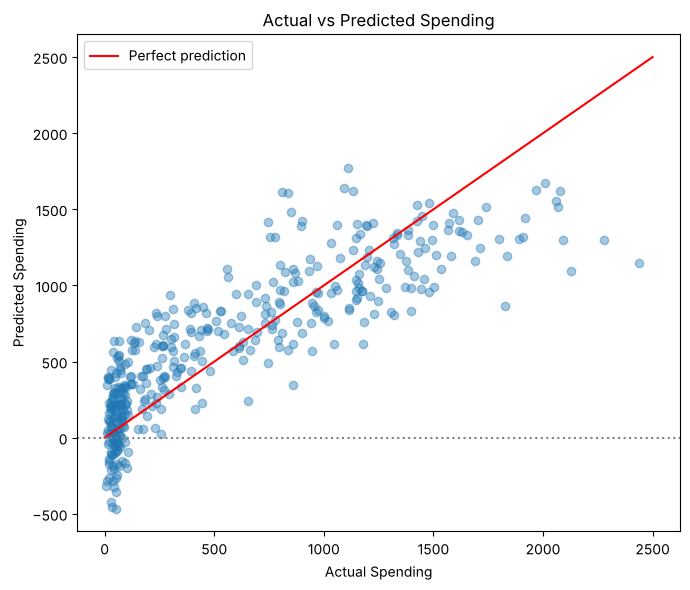

Predictions below zero: 46 out of 406


In [10]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred, alpha=0.4)
plt.plot([0, 2500], [0, 2500], color="red", label="Perfect prediction")
plt.axhline(0, color="gray", linestyle=":")
plt.xlabel("Actual Spending")
plt.ylabel("Predicted Spending")
plt.title("Actual vs Predicted Spending")
plt.legend()
plt.tight_layout()
plt.show()

print("Predictions below zero:", (y_pred < 0).sum(), "out of", len(y_pred))

**What it explains:** Points follow the red line in general, but they spread out for big spenders.
Some low-income customers get a **negative** prediction, which is impossible. This happens because spending is curved (it grows faster at high income), while Linear Regression can only draw a straight line. On the website we show 0 for these cases.

## Step 9: Errors (residuals) graph

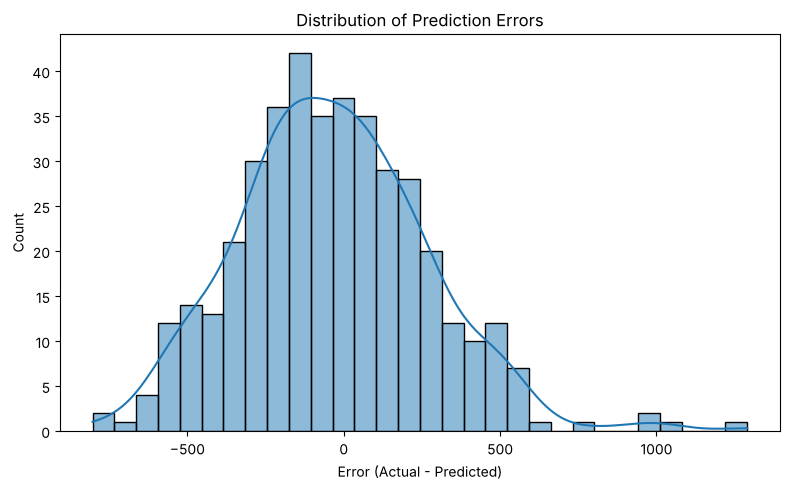

Share of predictions within 300 of the real value: 70.7 %


In [11]:
errors = y_test - y_pred

plt.figure(figsize=(8, 5))
sns.histplot(errors, bins=30, kde=True)
plt.xlabel("Error (Actual - Predicted)")
plt.title("Distribution of Prediction Errors")
plt.tight_layout()
plt.show()

print("Share of predictions within 300 of the real value:", round((abs(errors) <= 300).mean() * 100, 1), "%")

## Interpretation
- **R² = 0.72** → the model explains about **72%** of the differences in customer spending. This is good for real customer data, where people's behaviour is hard to predict.
- **MAE ≈ 239** → on average the prediction is about 239 away from the real spending.
- About **71%** of predictions are within 300 of the real value.
- **Limitation:** spending is skewed and curved, so a straight line cannot capture everything and sometimes predicts below zero.

In [12]:
print("LINEAR REGRESSION SUMMARY")
print("-" * 30)
print("Total customers :", len(df))
print("Train customers :", len(X_train))
print("Test customers  :", len(X_test))
print("MAE             :", round(mae, 2))
print("RMSE            :", round(rmse, 2))
print("R2 Score        :", round(r2, 4))

LINEAR REGRESSION SUMMARY
------------------------------
Total customers : 2030
Train customers : 1624
Test customers  : 406
MAE             : 238.56
RMSE            : 303.52
R2 Score        : 0.7189
